In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format='retina'

import sys
sys.path.append("../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import scanpy as sc
import pandas as pd
import seaborn as sns

In [3]:
sc.settings.set_figure_params(dpi_save=1200, vector_friendly=True, fontsize=18)
plt.rcParams['axes.grid'] = False
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [4]:
from decipher_model import DecipherConfig, Decipher
from decipher_training import train_simple
from load_data import load_datasets, palette_original
from post_analysis import (
    rotate_decipher_space,
    cluster_representations,
    compute_trajectories,
    gene_patterns_from_decipher_trajectory,
    compute_decipher_time,
    compute_decipher_gene_correlation,
)
from post_analysis_plotting import (
    plot_decipher_v,
    plot_trajectory,
    plot_gene_patterns,
    add_cell_type_band,
)

In [7]:
datasets = dict()
for patient_name in [
    "dnm_09H058",  # AML 17
    "dnm_10H056",  # AML 16
    "dnm_11H240",  # AML 13
    "dnm_12H007",  # AML 15
    "dnm_12H010",  # AML 14
]:
    datasets[patient_name] = sc.read_h5ad(f"data/dnm/{patient_name}.preprocessed.h5")

In [8]:
models = dict()

V4
[Epoch 0000]  Loss: 52550059.21265


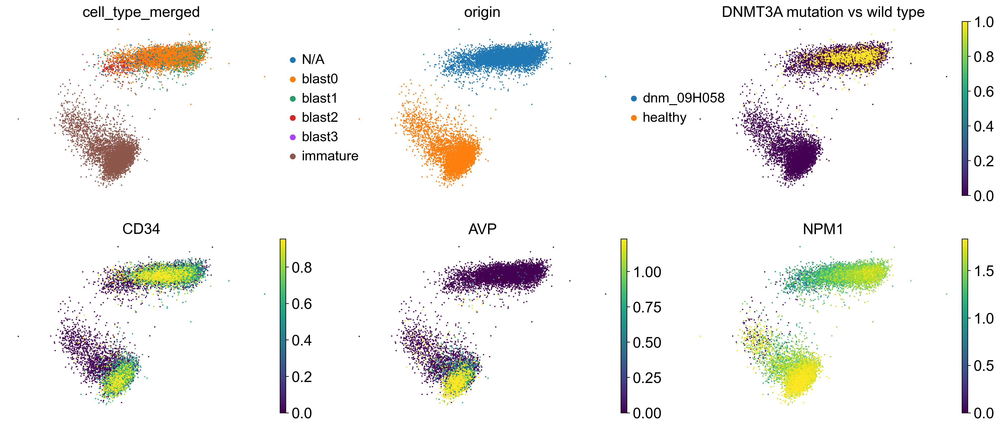

[Epoch 0001]  Loss: 46672124.93494
[Epoch 0002]  Loss: 42584371.57264
[Epoch 0003]  Loss: 41958525.66325
[Epoch 0004]  Loss: 41686571.15299
[Epoch 0005]  Loss: 41501545.37167
[Epoch 0006]  Loss: 41267586.05877
[Epoch 0007]  Loss: 41069413.77600
[Epoch 0008]  Loss: 40933717.91197
[Epoch 0009]  Loss: 40851692.78857
[Epoch 0010]  Loss: 40751374.21611


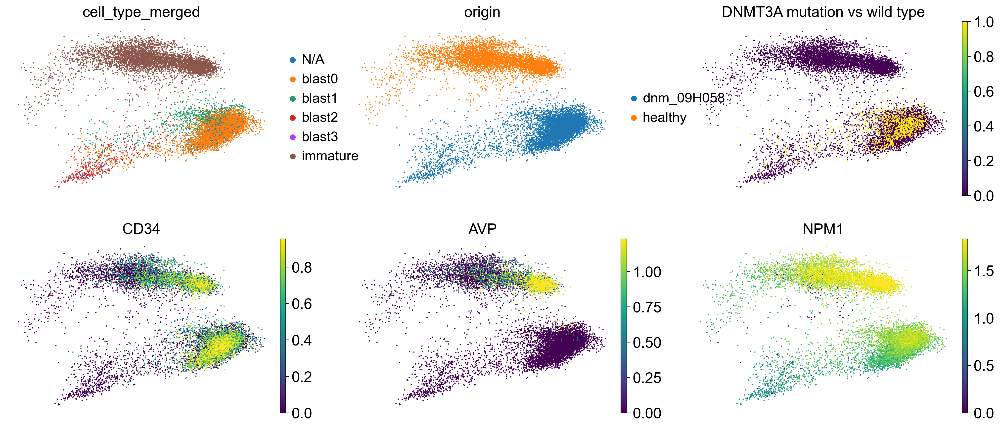

[Epoch 0011]  Loss: 40686647.61509
[Epoch 0012]  Loss: 40634638.73508
[Epoch 0013]  Loss: 40587374.69883
[Epoch 0014]  Loss: 40536236.63964
[Epoch 0015]  Loss: 40491704.12525
[Epoch 0016]  Loss: 40464812.57638
[Epoch 0017]  Loss: 40476644.67963
[Epoch 0018]  Loss: 40426923.31518
[Epoch 0019]  Loss: 40402749.11076
[Epoch 0020]  Loss: 40390253.44984


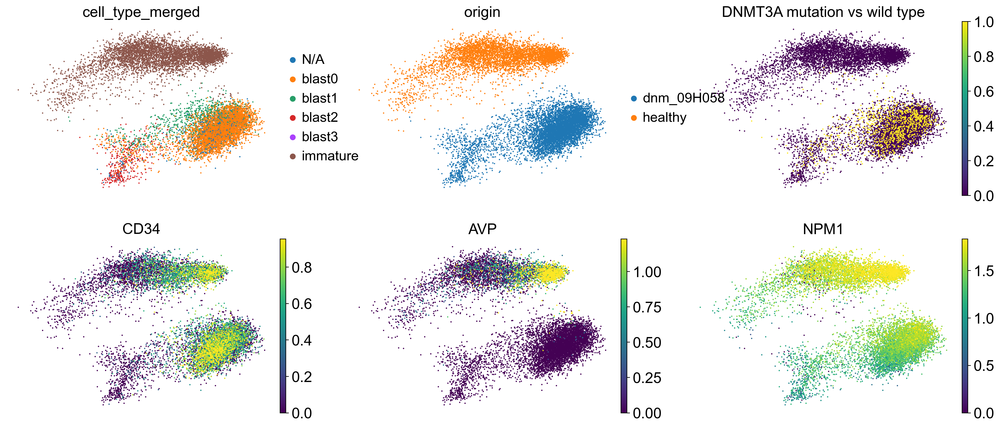

[Epoch 0021]  Loss: 40376883.17143
[Epoch 0022]  Loss: 40392991.67919
[Epoch 0023]  Loss: 40363991.16063
[Epoch 0024]  Loss: 40321092.88887
[Epoch 0025]  Loss: 40297777.31534
[Epoch 0026]  Loss: 40283192.30546
[Epoch 0027]  Loss: 40275479.43923
[Epoch 0028]  Loss: 40289925.19438
[Epoch 0029]  Loss: 40246837.35471
[Epoch 0030]  Loss: 40230296.51231


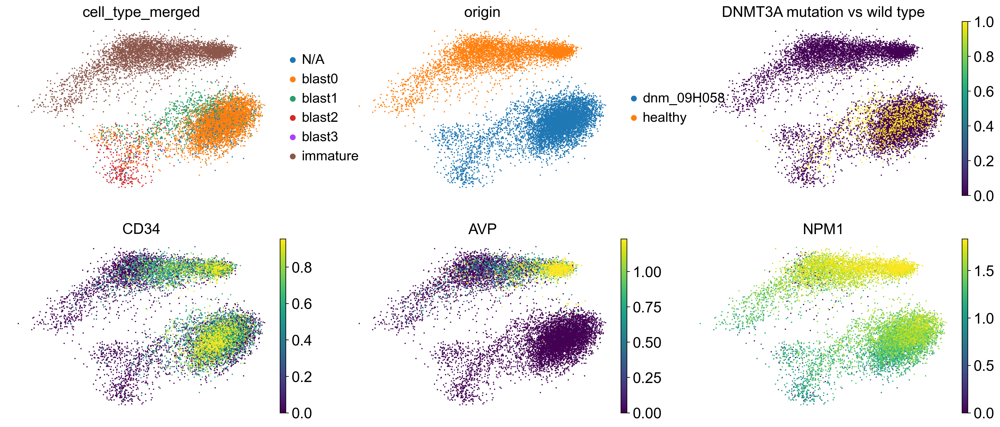

[Epoch 0031]  Loss: 40255416.98109
[Epoch 0032]  Loss: 40237383.59285
[Epoch 0033]  Loss: 40199869.29796
[Epoch 0034]  Loss: 40191331.11987
[Epoch 0035]  Loss: 40185009.09845
[Epoch 0036]  Loss: 40180358.52580
[Epoch 0037]  Loss: 40169962.59587
[Epoch 0038]  Loss: 40159927.49631
[Epoch 0039]  Loss: 40147356.03761
[Epoch 0040]  Loss: 40141184.64401


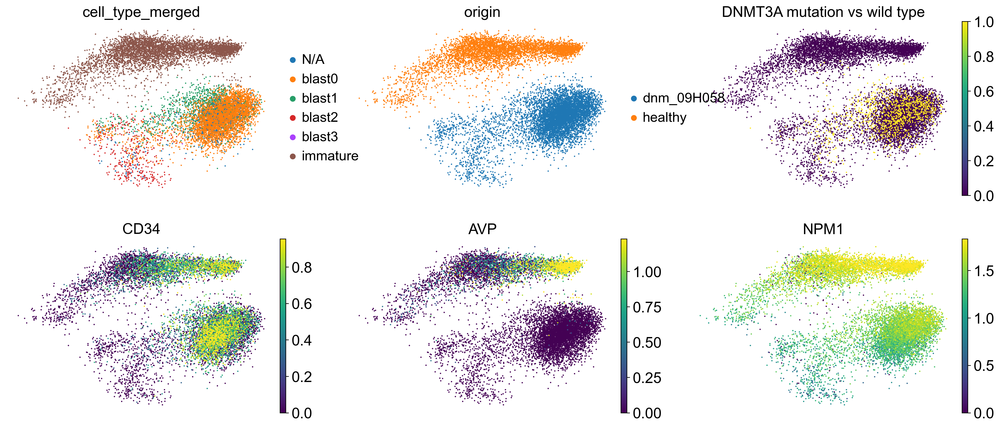

[Epoch 0041]  Loss: 40135835.83837
[Epoch 0042]  Loss: 40126513.24328
[Epoch 0043]  Loss: 40124534.68732
[Epoch 0044]  Loss: 40110600.80441
[Epoch 0045]  Loss: 40105382.97402
[Epoch 0046]  Loss: 40122712.83926
[Epoch 0047]  Loss: 40100716.57378
[Epoch 0048]  Loss: 40092421.77177
[Epoch 0049]  Loss: 40081356.03859
[Epoch 0050]  Loss: 40069667.60970


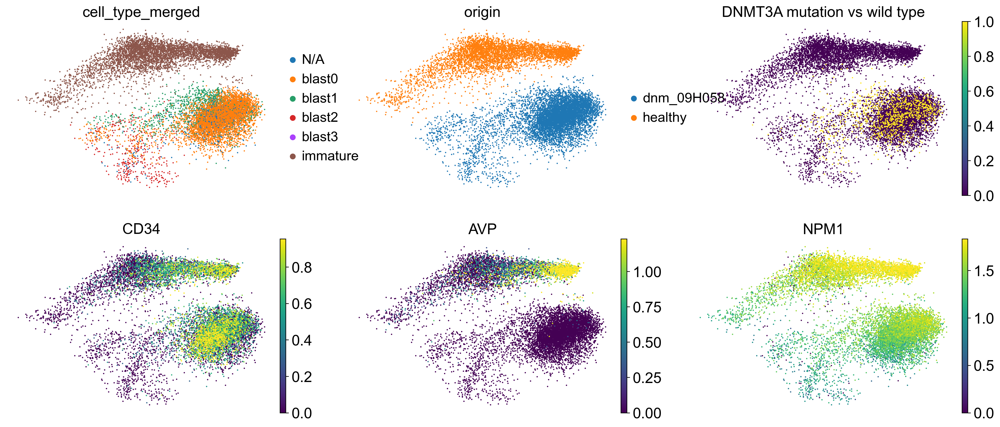

[Epoch 0051]  Loss: 40066846.42069
[Epoch 0052]  Loss: 40056613.13580
[Epoch 0053]  Loss: 40049012.93469
[Epoch 0054]  Loss: 40049650.49310
[Epoch 0055]  Loss: 40038128.38084
[Epoch 0056]  Loss: 40036950.82535
[Epoch 0057]  Loss: 40039389.07281
[Epoch 0058]  Loss: 40041146.58156
[Epoch 0059]  Loss: 40044014.81062
[Epoch 0060]  Loss: 40018000.38155


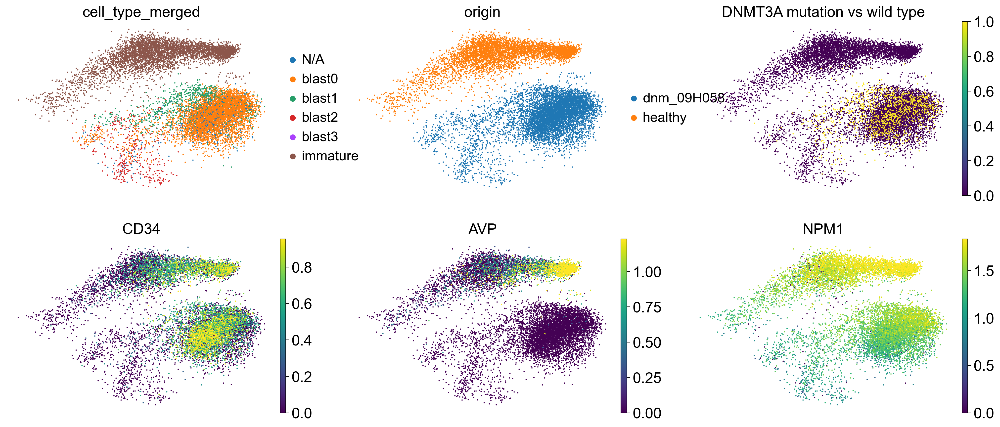

V4
[Epoch 0000]  Loss: 44516499.85838


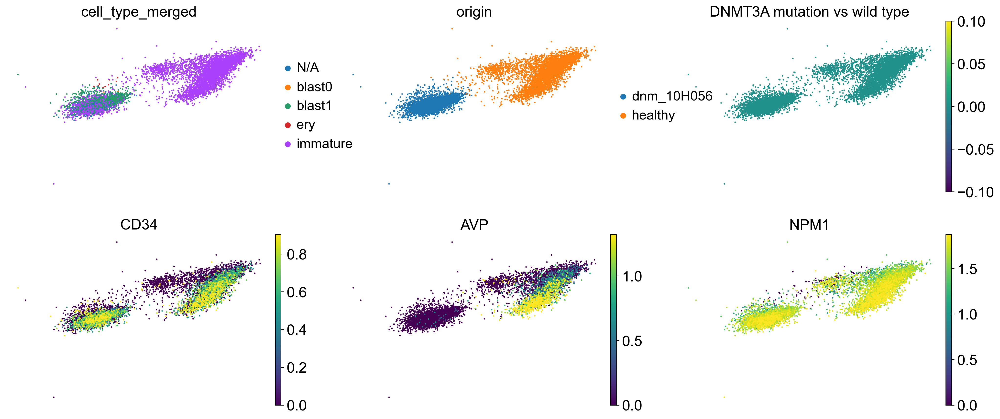

[Epoch 0001]  Loss: 37838723.85069
[Epoch 0002]  Loss: 34321333.45816
[Epoch 0003]  Loss: 33358906.87246
[Epoch 0004]  Loss: 32946297.16302
[Epoch 0005]  Loss: 32745464.65470
[Epoch 0006]  Loss: 32586265.53483
[Epoch 0007]  Loss: 32429163.29795
[Epoch 0008]  Loss: 32272481.40444
[Epoch 0009]  Loss: 32148028.20769
[Epoch 0010]  Loss: 32056011.51978


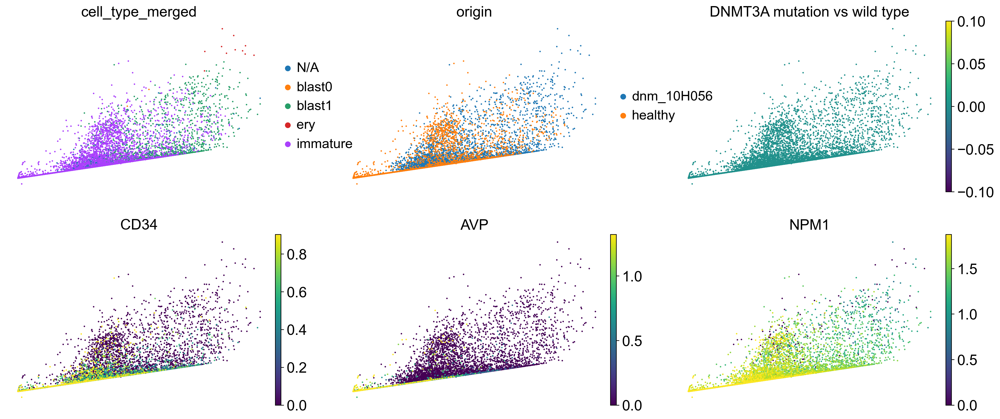

[Epoch 0011]  Loss: 31972542.14555
[Epoch 0012]  Loss: 31903681.01543
[Epoch 0013]  Loss: 31854181.37916
[Epoch 0014]  Loss: 31800886.65616
[Epoch 0015]  Loss: 31722355.09439
[Epoch 0016]  Loss: 31677022.27540
[Epoch 0017]  Loss: 31642266.99318
[Epoch 0018]  Loss: 31594887.08976
[Epoch 0019]  Loss: 31565651.73667
[Epoch 0020]  Loss: 31549500.73917


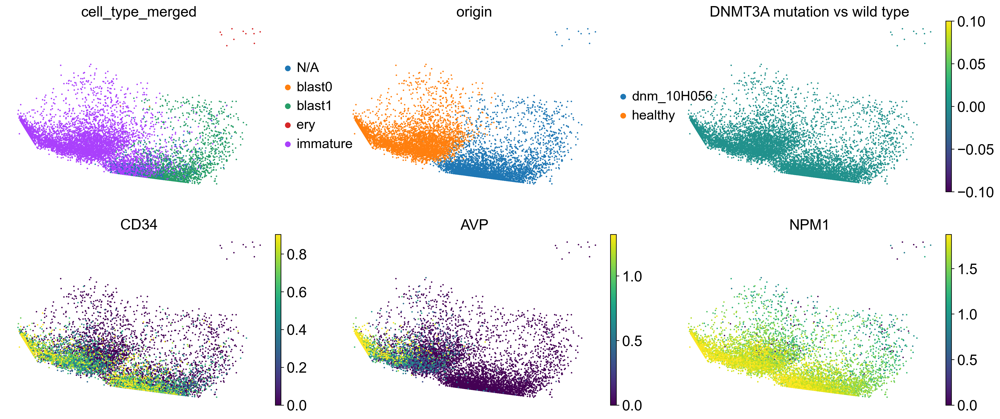

[Epoch 0021]  Loss: 31508137.02650
[Epoch 0022]  Loss: 31481878.17014
[Epoch 0023]  Loss: 31456823.22354
[Epoch 0024]  Loss: 31439325.41962
[Epoch 0025]  Loss: 31426470.59083
[Epoch 0026]  Loss: 31411940.43198
[Epoch 0027]  Loss: 31417976.66927
[Epoch 0028]  Loss: 31388758.26654
[Epoch 0029]  Loss: 31395998.53493
[Epoch 0030]  Loss: 31376224.25465


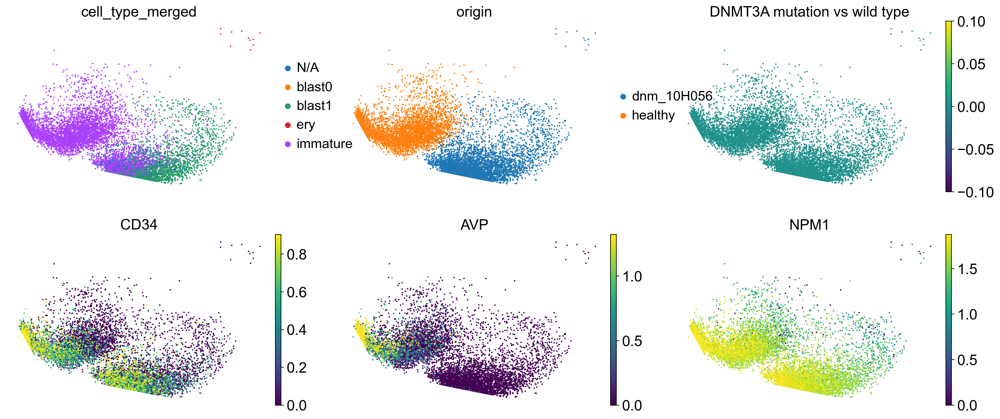

[Epoch 0031]  Loss: 31359997.10315
[Epoch 0032]  Loss: 31346162.78613
[Epoch 0033]  Loss: 31332834.30278
[Epoch 0034]  Loss: 31321823.89851
[Epoch 0035]  Loss: 31345557.56534
[Epoch 0036]  Loss: 31325544.65960
[Epoch 0037]  Loss: 31298800.16231
[Epoch 0038]  Loss: 31290264.21027
[Epoch 0039]  Loss: 31280232.64879
[Epoch 0040]  Loss: 31272826.14515


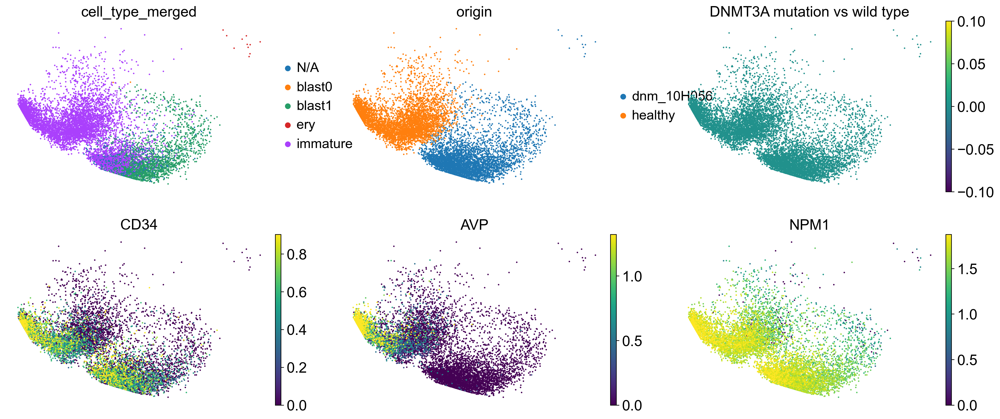

[Epoch 0041]  Loss: 31263046.17389
[Epoch 0042]  Loss: 31276805.44682
[Epoch 0043]  Loss: 31276346.11732
[Epoch 0044]  Loss: 31253207.99988
[Epoch 0045]  Loss: 31243070.15044
[Epoch 0046]  Loss: 31231310.77496
[Epoch 0047]  Loss: 31225379.65199
[Epoch 0048]  Loss: 31221789.31822
[Epoch 0049]  Loss: 31219502.85973
[Epoch 0050]  Loss: 31213277.38177


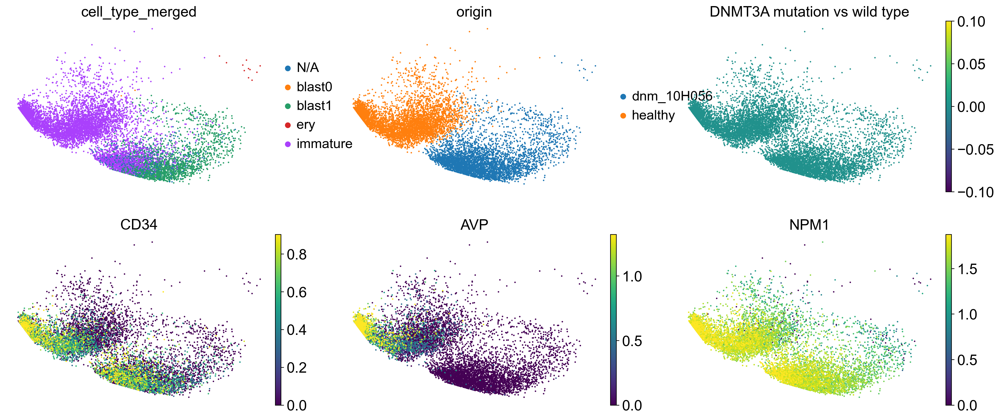

[Epoch 0051]  Loss: 31206416.83946
[Epoch 0052]  Loss: 31200916.97789
[Epoch 0053]  Loss: 31195646.79731
[Epoch 0054]  Loss: 31190951.27808
[Epoch 0055]  Loss: 31195245.92704
[Epoch 0056]  Loss: 31196007.04548
[Epoch 0057]  Loss: 31191269.64813
[Epoch 0058]  Loss: 31180545.44779
[Epoch 0059]  Loss: 31171688.96627
[Epoch 0060]  Loss: 31172945.37436


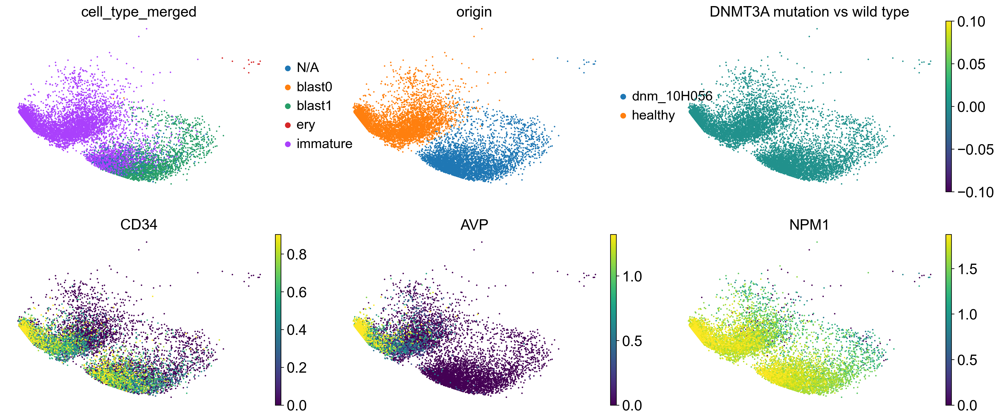

V4
[Epoch 0000]  Loss: 57004736.27510


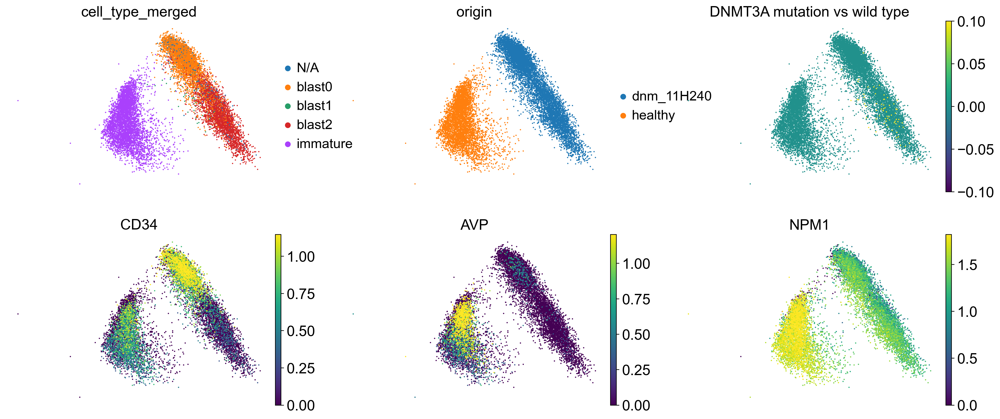

[Epoch 0001]  Loss: 49712662.12091
[Epoch 0002]  Loss: 46927294.84813
[Epoch 0003]  Loss: 46152747.43890
[Epoch 0004]  Loss: 45801709.25376
[Epoch 0005]  Loss: 45612051.24746
[Epoch 0006]  Loss: 45446884.87477
[Epoch 0007]  Loss: 45310879.86687
[Epoch 0008]  Loss: 45177619.39171
[Epoch 0009]  Loss: 45064564.72973
[Epoch 0010]  Loss: 44967027.60582


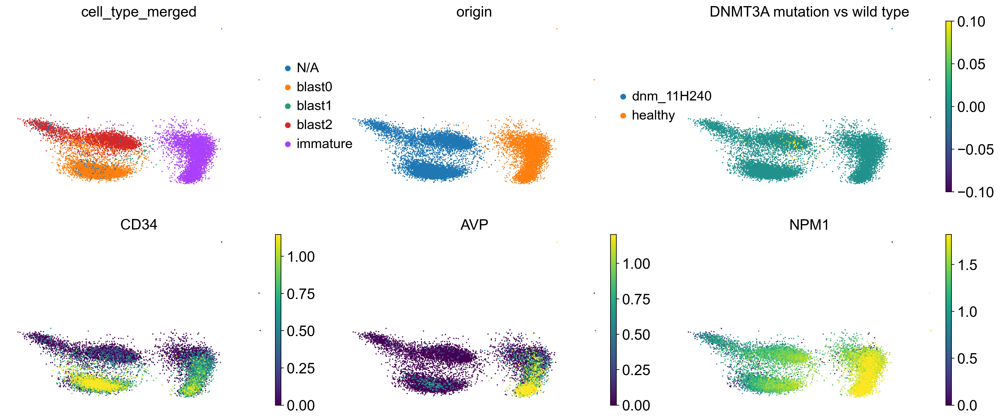

[Epoch 0011]  Loss: 44892324.38227
[Epoch 0012]  Loss: 44864176.18647
[Epoch 0013]  Loss: 44784184.88320
[Epoch 0014]  Loss: 44731894.74950
[Epoch 0015]  Loss: 44705060.63756
[Epoch 0016]  Loss: 44654346.90859
[Epoch 0017]  Loss: 44617528.11547
[Epoch 0018]  Loss: 44583044.75276
[Epoch 0019]  Loss: 44547525.74561
[Epoch 0020]  Loss: 44538093.95936


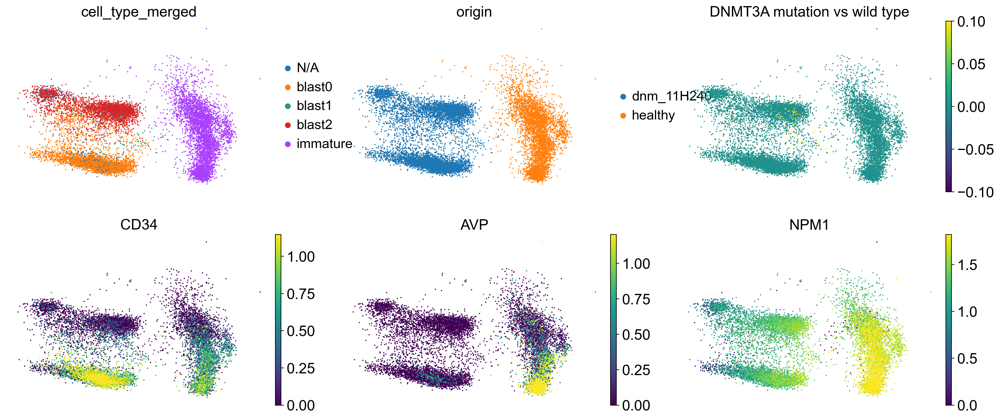

[Epoch 0021]  Loss: 44494929.73476
[Epoch 0022]  Loss: 44492804.14184
[Epoch 0023]  Loss: 44454309.08381
[Epoch 0024]  Loss: 44422394.40077
[Epoch 0025]  Loss: 44401146.40305
[Epoch 0026]  Loss: 44394688.01094
[Epoch 0027]  Loss: 44400818.75878
[Epoch 0028]  Loss: 44416714.49208
[Epoch 0029]  Loss: 44348946.44491
[Epoch 0030]  Loss: 44332860.55634


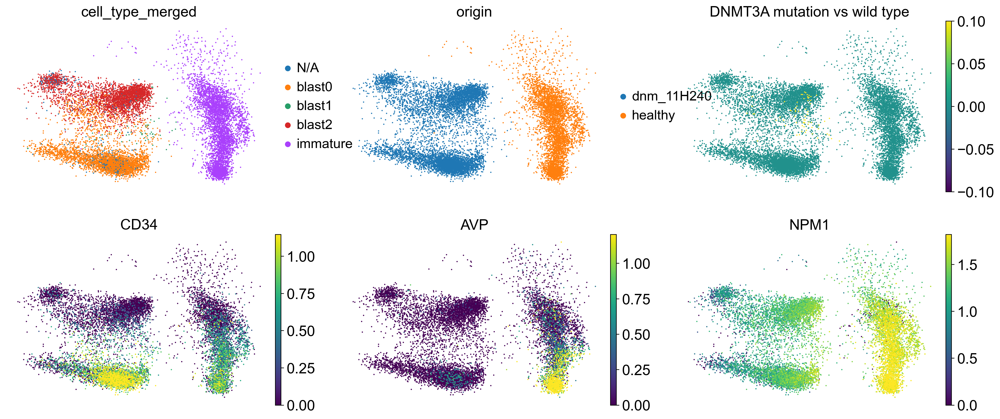

[Epoch 0031]  Loss: 44325799.48172
[Epoch 0032]  Loss: 44307905.92696
[Epoch 0033]  Loss: 44301685.78699
[Epoch 0034]  Loss: 44294814.27599
[Epoch 0035]  Loss: 44275367.43695
[Epoch 0036]  Loss: 44265732.77665
[Epoch 0037]  Loss: 44280068.18735
[Epoch 0038]  Loss: 44261710.29331
[Epoch 0039]  Loss: 44246467.26022
[Epoch 0040]  Loss: 44235923.16238


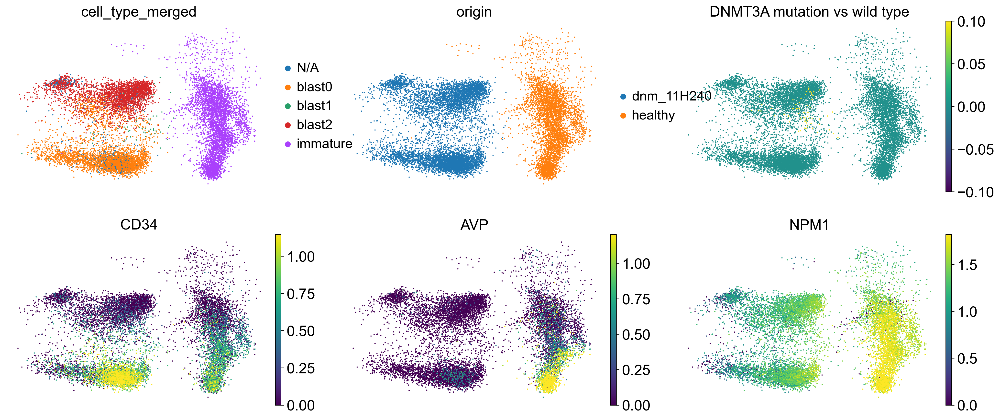

[Epoch 0041]  Loss: 44228285.54302
[Epoch 0042]  Loss: 44225393.11373
[Epoch 0043]  Loss: 44215486.12940
[Epoch 0044]  Loss: 44221949.11694
[Epoch 0045]  Loss: 44208089.28965
[Epoch 0046]  Loss: 44209797.75696
[Epoch 0047]  Loss: 44210709.87674
[Epoch 0048]  Loss: 44197852.86980
[Epoch 0049]  Loss: 44192980.67424
[Epoch 0050]  Loss: 44215066.24082


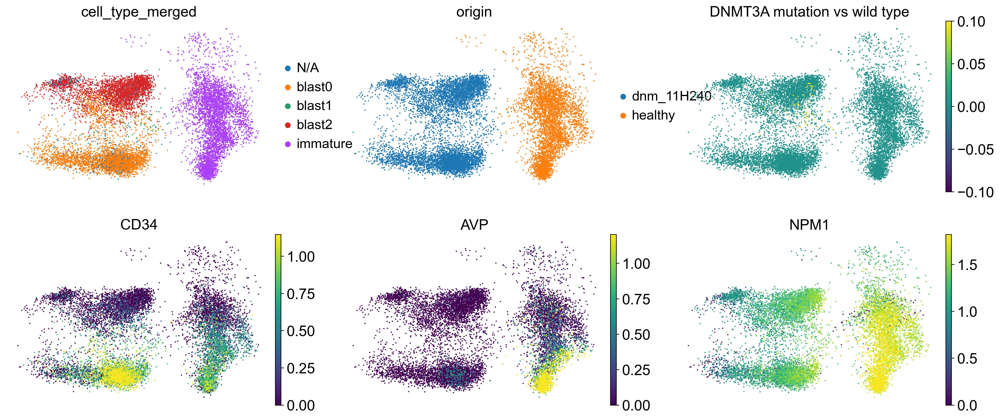

[Epoch 0051]  Loss: 44239585.00099
[Epoch 0052]  Loss: 44193505.67961
[Epoch 0053]  Loss: 44194670.78837
[Epoch 0054]  Loss: 44180661.76705
[Epoch 0055]  Loss: 44182885.57188
[Epoch 0056]  Loss: 44184335.97545
[Epoch 0057]  Loss: 44172855.93637
[Epoch 0058]  Loss: 44178924.79814
[Epoch 0059]  Loss: 44178302.21101
[Epoch 0060]  Loss: 44172219.10781


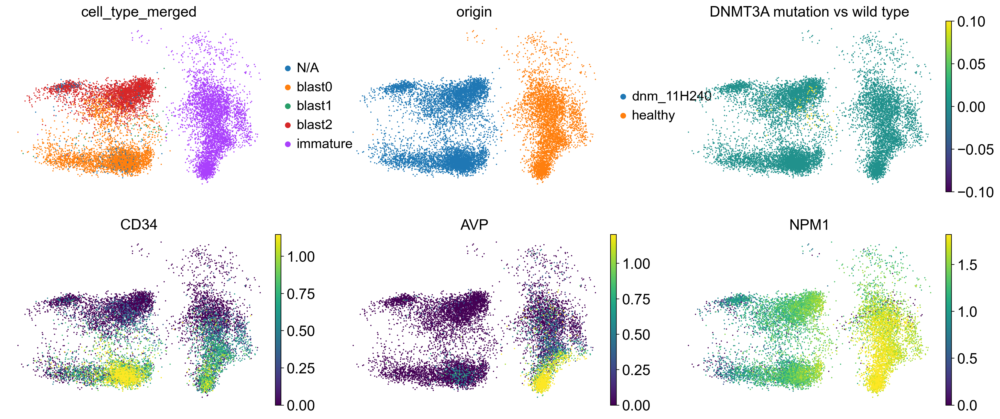

V4
[Epoch 0000]  Loss: 36783137.50636


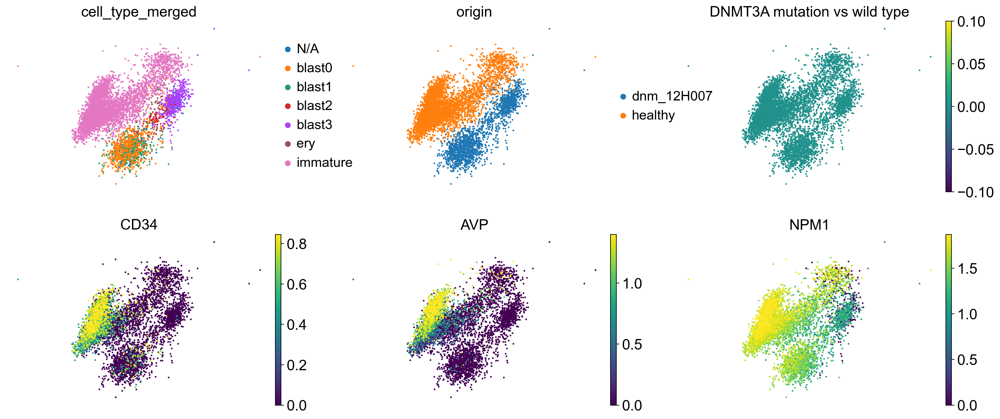

[Epoch 0001]  Loss: 35648580.66920
[Epoch 0002]  Loss: 27832107.21660
[Epoch 0003]  Loss: 26706140.22942
[Epoch 0004]  Loss: 26146333.35830
[Epoch 0005]  Loss: 25843714.22617
[Epoch 0006]  Loss: 25652437.97575
[Epoch 0007]  Loss: 25515959.99439
[Epoch 0008]  Loss: 25400244.14651
[Epoch 0009]  Loss: 25285360.21522
[Epoch 0010]  Loss: 25184602.04628


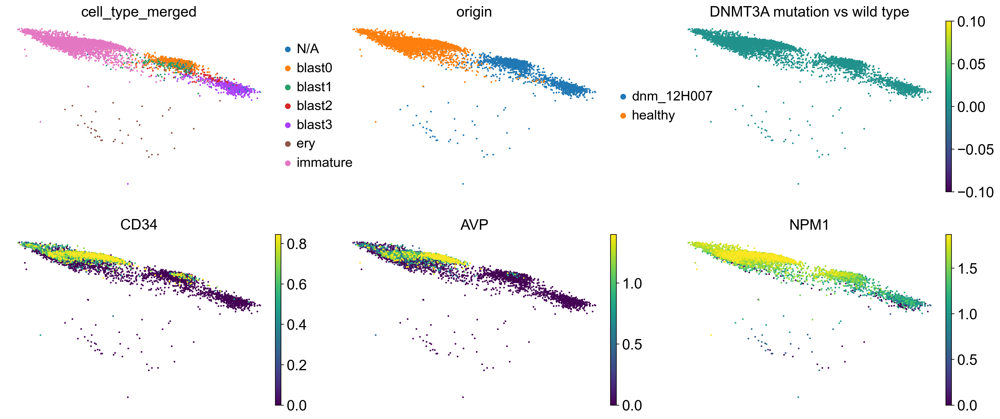

[Epoch 0011]  Loss: 25097529.17363
[Epoch 0012]  Loss: 25026290.26904
[Epoch 0013]  Loss: 25010272.14628
[Epoch 0014]  Loss: 24937897.60684
[Epoch 0015]  Loss: 24869394.64288
[Epoch 0016]  Loss: 24830118.92413
[Epoch 0017]  Loss: 24785460.06619
[Epoch 0018]  Loss: 24755994.24374
[Epoch 0019]  Loss: 24720880.40426
[Epoch 0020]  Loss: 24695820.10800


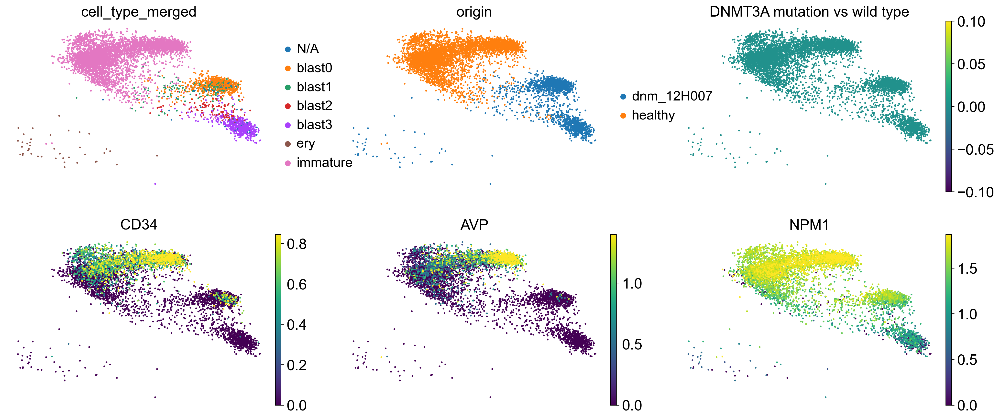

[Epoch 0021]  Loss: 24654530.33835
[Epoch 0022]  Loss: 24629190.06538
[Epoch 0023]  Loss: 24596196.05626
[Epoch 0024]  Loss: 24573878.86882
[Epoch 0025]  Loss: 24548459.14114
[Epoch 0026]  Loss: 24526383.24535
[Epoch 0027]  Loss: 24507710.87487
[Epoch 0028]  Loss: 24491260.09748
[Epoch 0029]  Loss: 24479165.79652
[Epoch 0030]  Loss: 24470377.07288


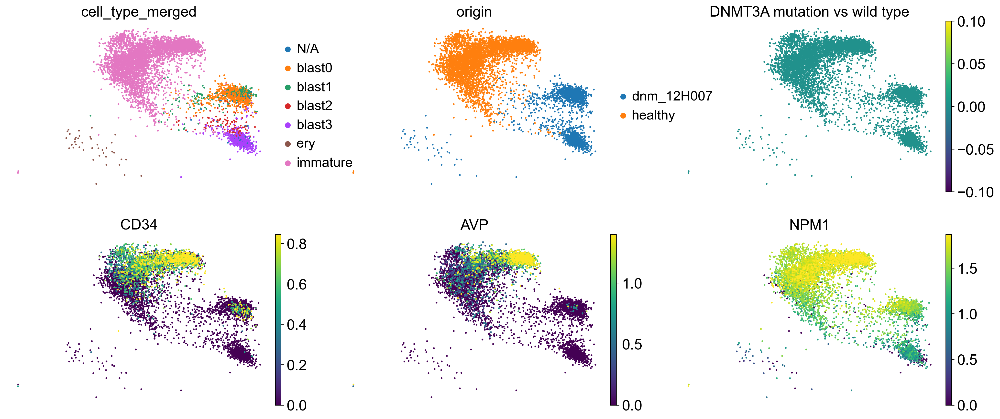

[Epoch 0031]  Loss: 24451628.82704
[Epoch 0032]  Loss: 24444455.61880
[Epoch 0033]  Loss: 24424332.76617
[Epoch 0034]  Loss: 24412814.85049
[Epoch 0035]  Loss: 24407205.87561
[Epoch 0036]  Loss: 24408584.43491
[Epoch 0037]  Loss: 24392011.93517
[Epoch 0038]  Loss: 24379768.97870
[Epoch 0039]  Loss: 24372430.78957
[Epoch 0040]  Loss: 24375211.69255


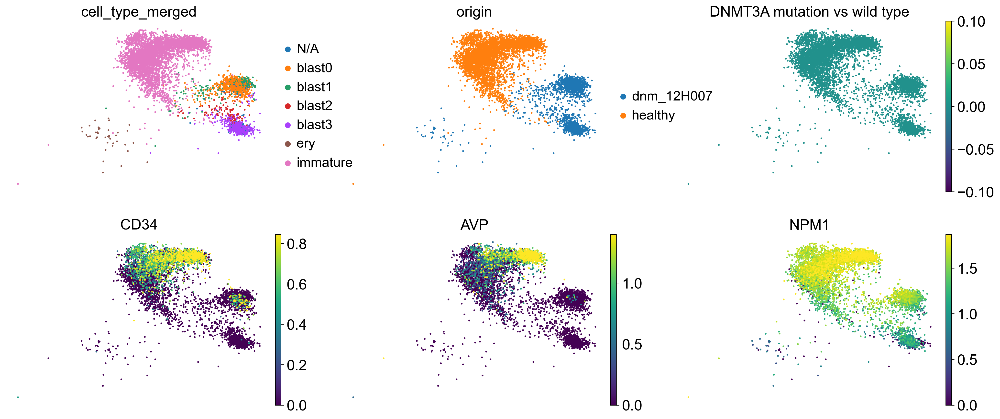

[Epoch 0041]  Loss: 24362870.38647
[Epoch 0042]  Loss: 24356620.33398
[Epoch 0043]  Loss: 24347839.97320
[Epoch 0044]  Loss: 24340416.07707
[Epoch 0045]  Loss: 24336971.53008
[Epoch 0046]  Loss: 24328946.21727
[Epoch 0047]  Loss: 24327202.73293
[Epoch 0048]  Loss: 24348081.30902
[Epoch 0049]  Loss: 24338130.86823
[Epoch 0050]  Loss: 24320892.15865


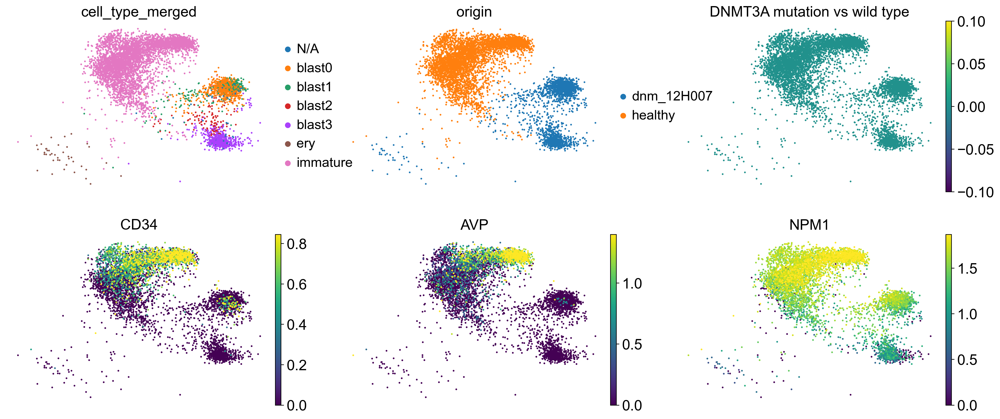

[Epoch 0051]  Loss: 24308765.80994
[Epoch 0052]  Loss: 24304852.26897
[Epoch 0053]  Loss: 24298251.55598
[Epoch 0054]  Loss: 24295824.84544
[Epoch 0055]  Loss: 24291169.82415
[Epoch 0056]  Loss: 24284253.01908
[Epoch 0057]  Loss: 24283667.08585
[Epoch 0058]  Loss: 24280167.19137
[Epoch 0059]  Loss: 24276987.80212
[Epoch 0060]  Loss: 24279986.24802


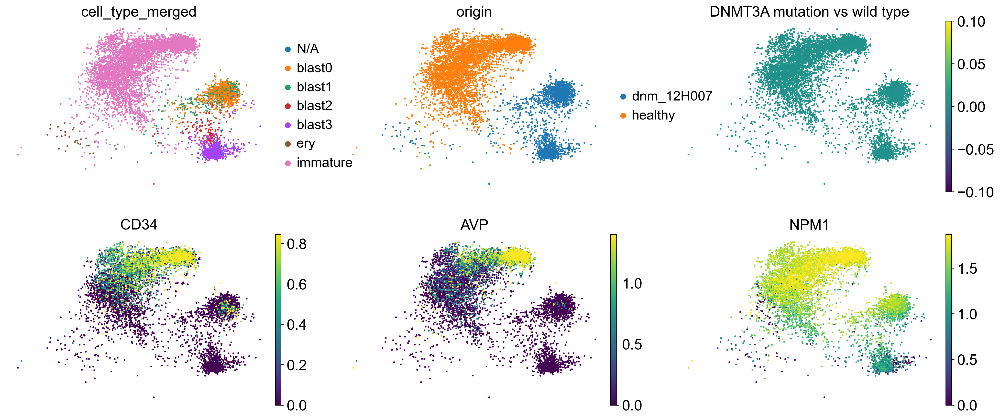

V4
[Epoch 0000]  Loss: 53895688.47501


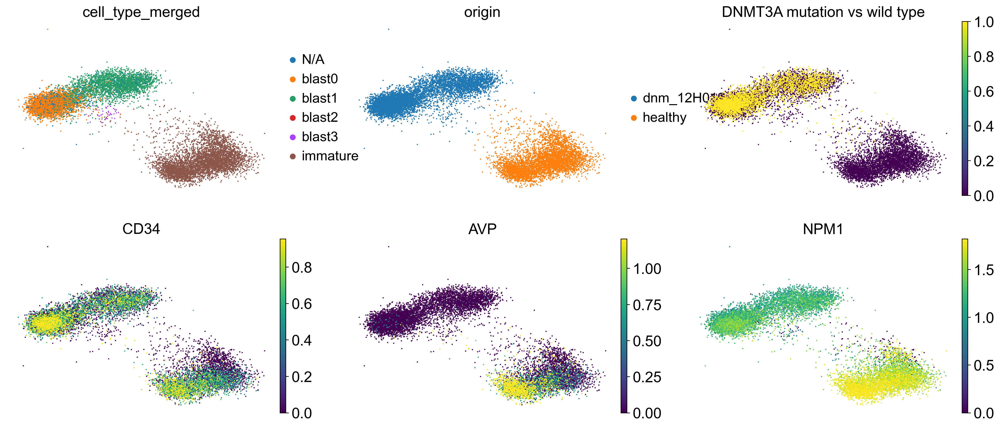

[Epoch 0001]  Loss: 45780155.57366
[Epoch 0002]  Loss: 43792626.26085
[Epoch 0003]  Loss: 43236286.12585
[Epoch 0004]  Loss: 42869380.07528
[Epoch 0005]  Loss: 42681387.01551
[Epoch 0006]  Loss: 42537656.41631
[Epoch 0007]  Loss: 42418707.55990
[Epoch 0008]  Loss: 42383047.62310
[Epoch 0009]  Loss: 42280747.94370
[Epoch 0010]  Loss: 42202094.27563


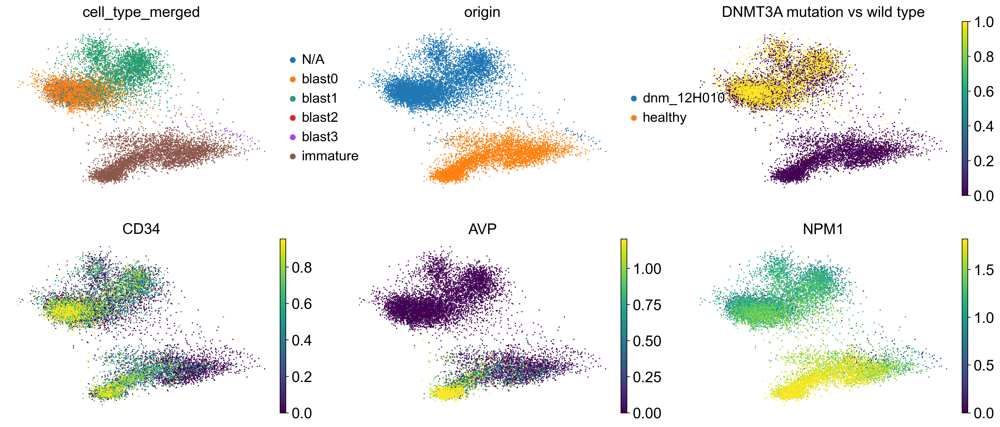

[Epoch 0011]  Loss: 42151283.49295
[Epoch 0012]  Loss: 42107649.99981
[Epoch 0013]  Loss: 42098053.72975
[Epoch 0014]  Loss: 42008006.72003
[Epoch 0015]  Loss: 41976940.02496
[Epoch 0016]  Loss: 41941416.94203
[Epoch 0017]  Loss: 41896495.53067
[Epoch 0018]  Loss: 41872758.39173
[Epoch 0019]  Loss: 41849184.38022
[Epoch 0020]  Loss: 41833193.97313


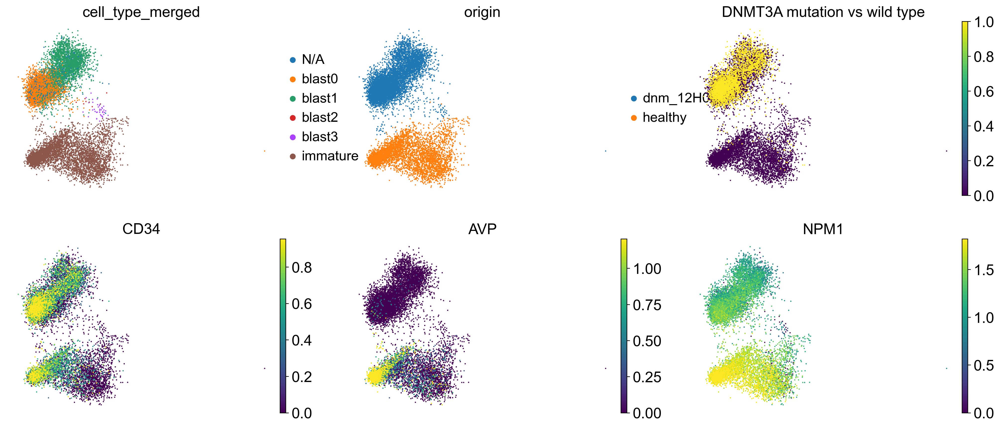

[Epoch 0021]  Loss: 41814911.90418
[Epoch 0022]  Loss: 41795007.36580
[Epoch 0023]  Loss: 41784166.84923
[Epoch 0024]  Loss: 41770152.51932
[Epoch 0025]  Loss: 41759051.20262
[Epoch 0026]  Loss: 41763398.25719
[Epoch 0027]  Loss: 41747806.30329
[Epoch 0028]  Loss: 41704271.35125
[Epoch 0029]  Loss: 41692229.94410
[Epoch 0030]  Loss: 41683297.69283


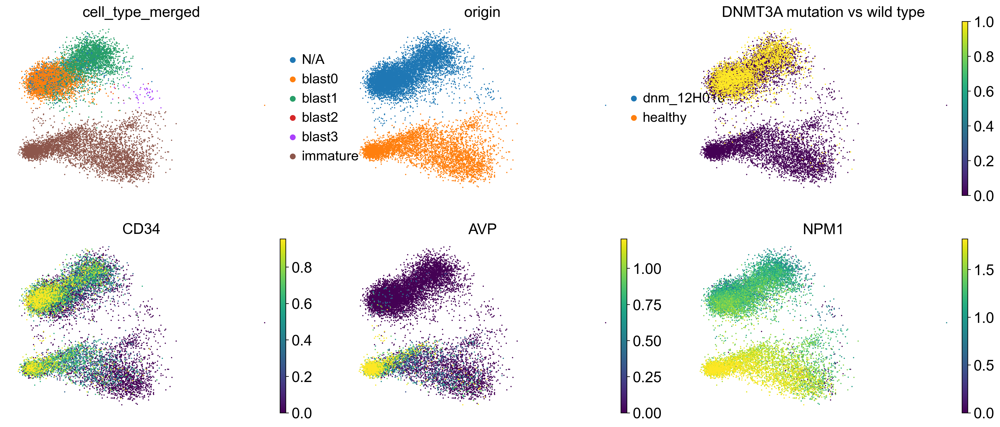

[Epoch 0031]  Loss: 41673068.75164
[Epoch 0032]  Loss: 41665628.80461
[Epoch 0033]  Loss: 41653364.54639
[Epoch 0034]  Loss: 41662569.91593
[Epoch 0035]  Loss: 41644561.12112
[Epoch 0036]  Loss: 41626759.02229
[Epoch 0037]  Loss: 41621414.63320
[Epoch 0038]  Loss: 41613350.27053
[Epoch 0039]  Loss: 41634630.28495
[Epoch 0040]  Loss: 41604787.09404


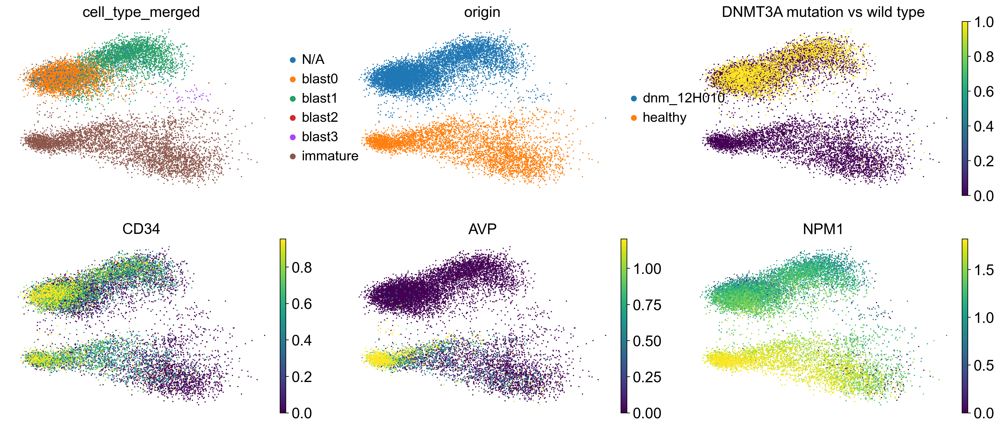

[Epoch 0041]  Loss: 41594133.86390
[Epoch 0042]  Loss: 41602281.63222
[Epoch 0043]  Loss: 41586768.43475
[Epoch 0044]  Loss: 41576882.66278
[Epoch 0045]  Loss: 41577253.56156
[Epoch 0046]  Loss: 41579973.20524
[Epoch 0047]  Loss: 41571947.62517
[Epoch 0048]  Loss: 41557867.05147
[Epoch 0049]  Loss: 41555430.62350
[Epoch 0050]  Loss: 41551869.06694


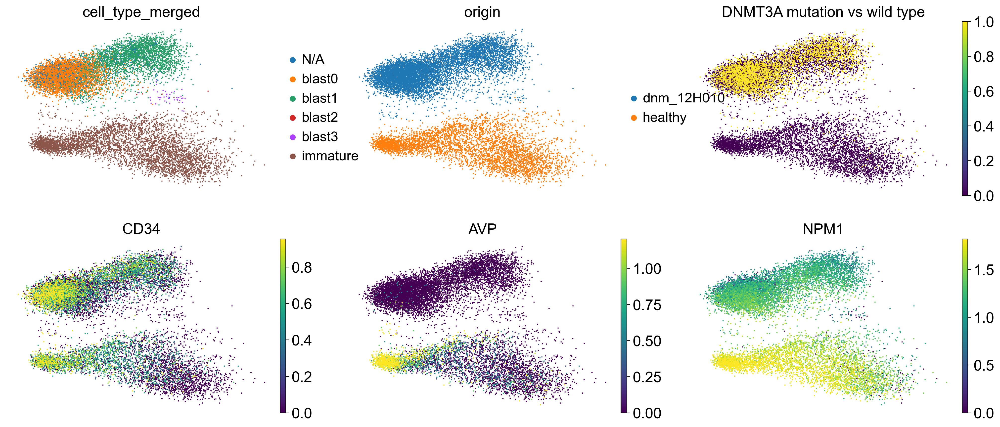

[Epoch 0051]  Loss: 41554977.08177
[Epoch 0052]  Loss: 41542802.31649
[Epoch 0053]  Loss: 41552556.49885
[Epoch 0054]  Loss: 41543558.96732
[Epoch 0055]  Loss: 41531748.06437
[Epoch 0056]  Loss: 41532300.01550
[Epoch 0057]  Loss: 41530608.48560
[Epoch 0058]  Loss: 41536083.44536
[Epoch 0059]  Loss: 41521449.18234
[Epoch 0060]  Loss: 41515332.24826


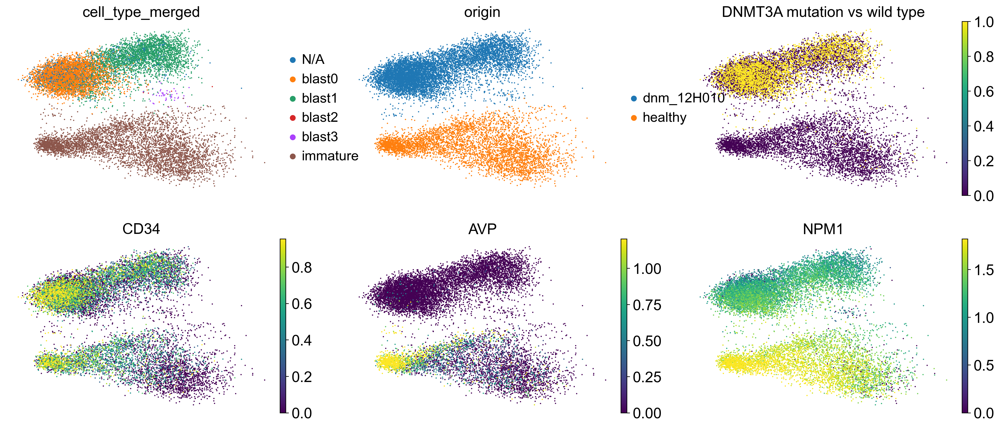

In [9]:
for patient_name, adata in datasets.items():
    seed = 0
    batch_size = 512
    learning_rate = 1e-2
    scale_factor = float(np.round(adata.shape[0] / batch_size, 3))

    decipher_config = DecipherConfig(
        scale_factor=scale_factor,
        seed=seed,
        beta=1e-1,
    )

    model = train_simple(
        adata,
        decipher_config,
        learning_rate=learning_rate,
        batch_size=batch_size,
        n_epochs=61,
        plot_every_k_epoch=10,
        plot_kwargs=dict(
            color=[
                "cell_type_merged",
                "origin",
                "DNMT3A mutation vs wild type",
                "CD34",
                "AVP",
                "NPM1",
            ],
            ncols=3,
            vmax=lambda xs: np.quantile(xs, 0.95),
            vmin=0.0,
        ),
    )

    models[patient_name] = model

In [9]:
for patient_name in models:
    model, adata = models[patient_name]
    sc.write(f"data/dnm/{patient_name}.decipher.h5ad", adata)
    torch.save(model.state_dict(), f"data/dnm/{patient_name}.decipher.pth")

In [11]:
models.keys()

dict_keys(['dnm_09H058', 'dnm_10H056', 'dnm_11H240', 'dnm_12H007'])

In [10]:
name_mapping = {
    "dnm_09H058": "AML17",
    "dnm_10H056": "AML16",
    "dnm_11H240": "AML13",
    "dnm_12H007": "AML15",
    "dnm_12H010": "AML14",
}

In [17]:
for patient_name, aml_name in name_mapping.items():
    model, adata = models[patient_name]
    adata = adata.copy()
    adata.obs["origin"] = adata.obs["origin"].replace(
        {patient_name: aml_name, "healthy": "Healthy"}
    )
    palette_original[aml_name] = palette_original["AML1"]

    adata.obs["origin_int"] = adata.obs["origin"].replace({aml_name: 1, "Healthy": 0})
    rotate_decipher_space(
        adata,
        "origin_int",
        decipher_component_to_align_label_with=2,
        flip_latent_z=True,
    )

    cluster_representations(adata, 2)
    normal_trajectory = compute_trajectories(
        adata,
        "AVP",
        "MPO",
        subset_column="origin",
        subset_value="Healthy",
        cell_types_key="cell_type_merged",
    )
    perturbed_trajectory = compute_trajectories(
        adata,
        "AVP",
        "CD68",
        subset_column="origin",
        subset_value=aml_name,
        cell_types_key="cell_type_merged",
    )

    compute_decipher_time(
        adata, {"Healthy": normal_trajectory, aml_name: perturbed_trajectory}
    )
    
    gene_patterns_from_decipher_trajectory(adata, model)

    # we now compare patterns only on their overlapping portions
    reference_times = None
    min_length = 1_000_000
    gene_patterns = []
    keys = []
    for key in adata.uns["decipher_gene_patterns"]:
        keys.append(key)
        patterns_df = adata.uns["decipher_gene_patterns"][key].T
        if patterns_df.shape[1] < min_length:
            reference_times = patterns_df.columns.values
            min_length = patterns_df.shape[1]
        gene_patterns.append(patterns_df.values)

    gene_patterns = np.stack([gg[:, :min_length] for gg in gene_patterns])
    adata.uns["decipher_gene_patterns_cropped"] = {
        "patterns": gene_patterns,
        "times": reference_times,
        "keys": keys,
    }
    
    sc.write(f"data/dnm/{patient_name}.post-analyzed.h5ad", adata)
    

/opt/miniconda3/envs/latent-manifold/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'origin' as categorical
/opt/miniconda3/envs/latent-manifold/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'origin' as categorical
/opt/miniconda3/envs/latent-manifold/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will

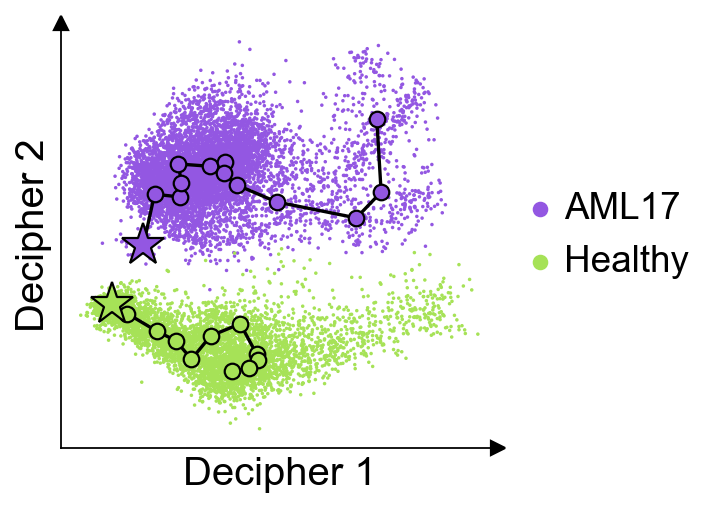

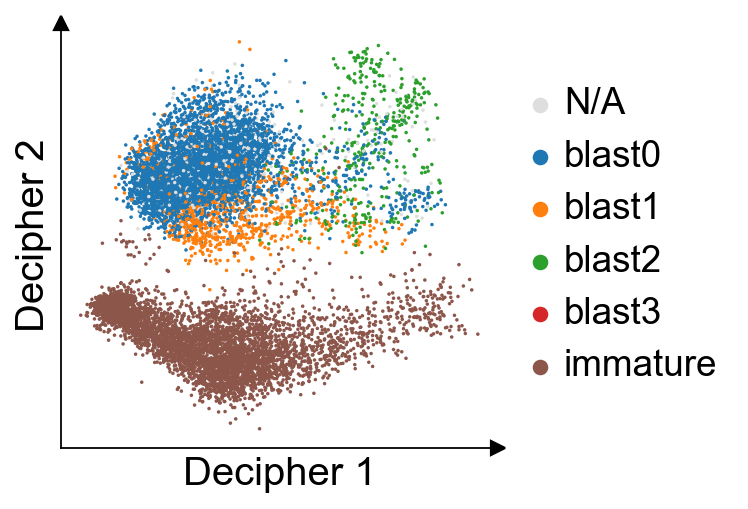

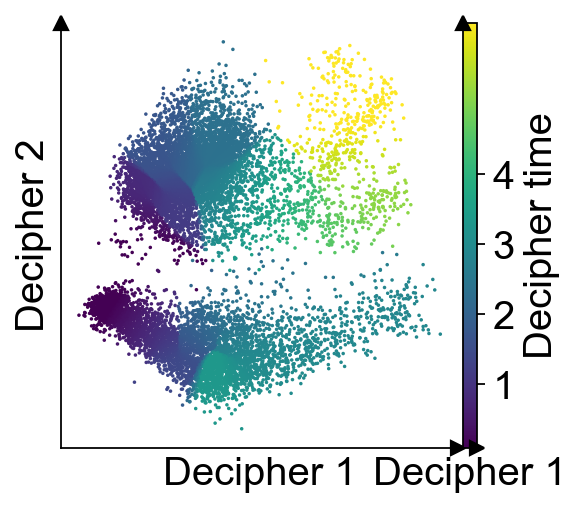

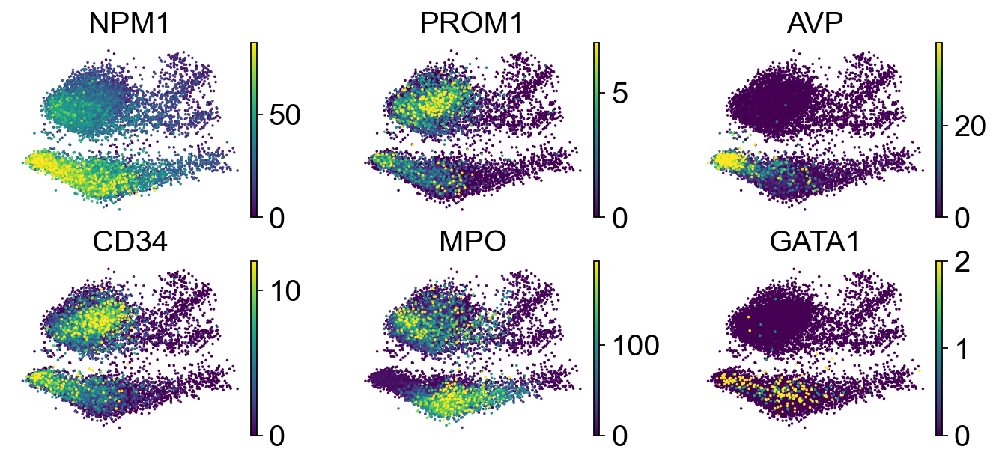

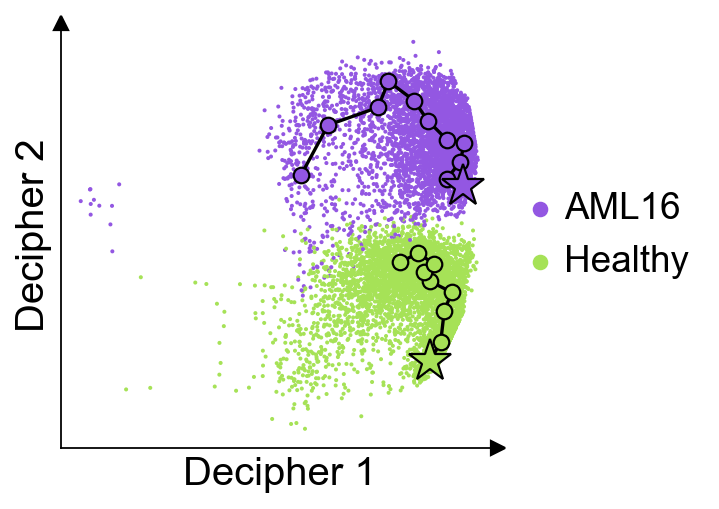

...

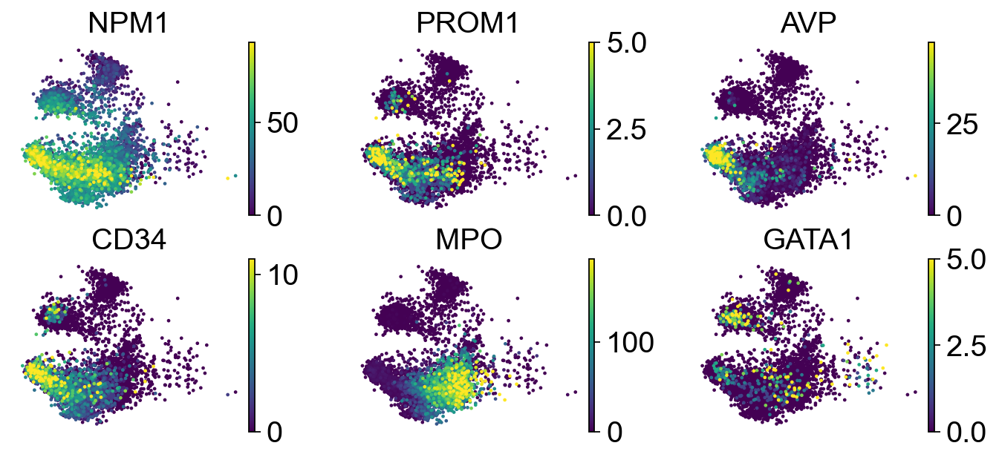

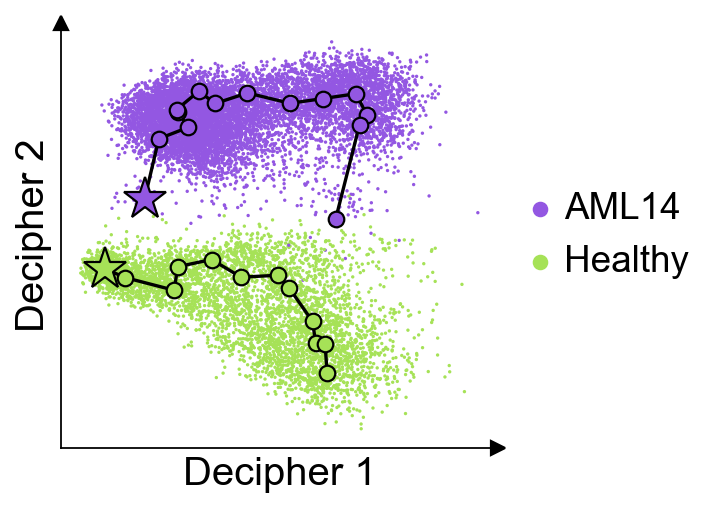

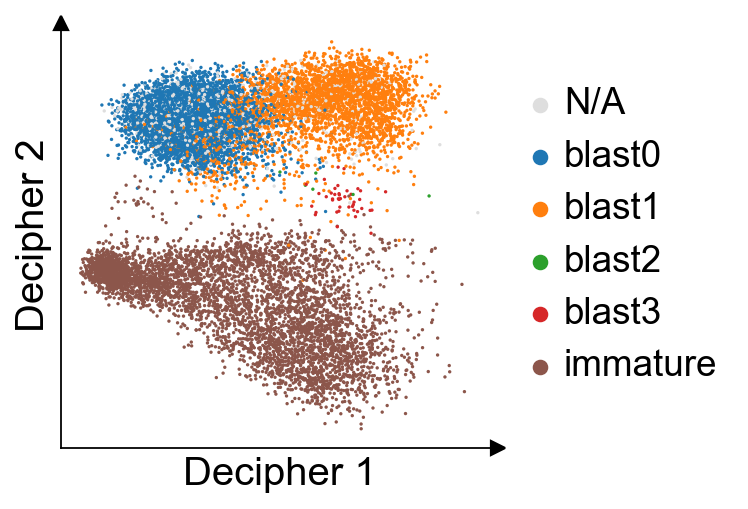

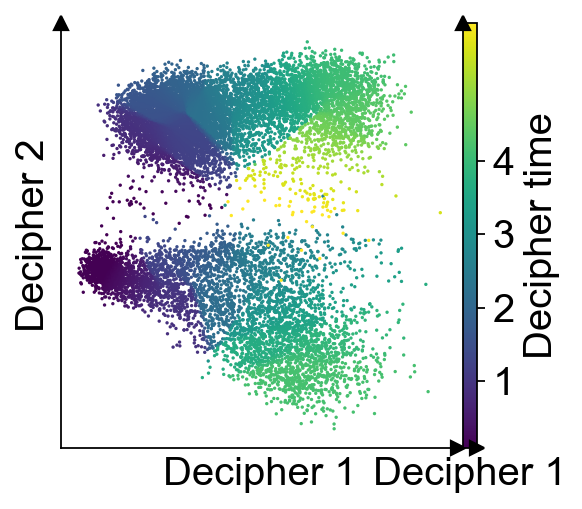

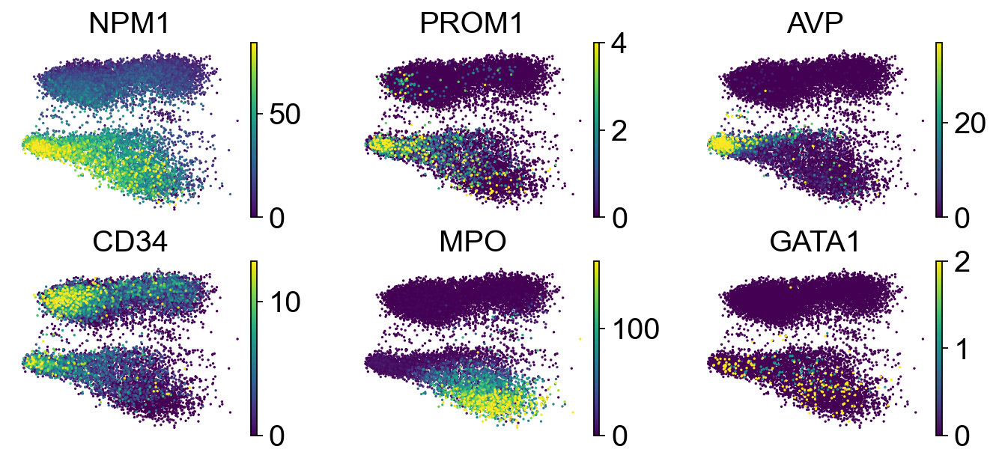

In [19]:
for patient_name, aml_name in name_mapping.items():
    model, _ = models[patient_name]
    adata = sc.read_h5ad(f"data/dnm/{patient_name}.post-analyzed.h5ad")
    
    adata.obs["origin"] = adata.obs["origin"].replace(
        {patient_name: aml_name, "healthy": "Healthy"}
    )
    fig = plot_decipher_v(adata, "origin", palette=palette_original)
    adata.uns["decipher_trajectories"]["origin=Healthy"]
    plot_trajectory(
        adata,
        "origin=Healthy",
        color=palette_original["Healthy"],
        ax=fig.axes[0],
    )
    plot_trajectory(
        adata,
        "origin=" + aml_name,
        color=palette_original["AML1"],
        ax=fig.axes[0],
    )
    plt.show()
#     fig.savefig(f"figures/figure5/DNM.decipher_space.origin.{patient_name}.pdf", bbox_inches="tight")
    fig = plot_decipher_v(adata, "cell_type_merged", palette=palette_original)
    plt.show()
#     fig.savefig(f"figures/figure5/DNM.decipher_space.cell_type.{patient_name}.pdf", bbox_inches="tight")
    
    
    fig = plot_decipher_v(adata, "decipher_time")
    fig.axes[0].collections[-1].colorbar.set_label("Decipher time")
    fig.axes[0].collections[-1].colorbar.set_ticks([0,1,2,3,4])
    plt.show()
#     fig.savefig(f"figures/figure5/DNM.decipher_space.decipher_time.{patient_name}.pdf", bbox_inches="tight")
    
    fig = plot_decipher_v(
        adata,
        ["NPM1", "PROM1", "AVP", "CD34", "MPO", "GATA1"],
        show_axis="no",
        ncols=3,
        vmax=lambda x: np.quantile(x, 0.99),
        figsize=(2.5, 2),
    )
    plt.show()
#     fig.savefig(f"figures/figure5/DNM.decipher_space.gene_expression.{patient_name}.pdf", bbox_inches="tight")

# gene patterns


In [22]:
from basis_decomposition.run import compute_basis_decomposition, InferenceMode, plot_basis, get_basis
import pickle



for i, patient_name in enumerate(
    ["dnm_09H058", "dnm_10H056", "dnm_11H240", "dnm_12H007", "dnm_12H010"]
):
    dnm_name = f"DNM{i+1}"
    model, _ = models[patient_name]
    adata = sc.read_h5ad(f"analysis/dnm/{patient_name}.post-analyzed.h5ad")
    gene_patterns = torch.FloatTensor(adata.uns["decipher_gene_patterns_cropped"]["patterns"])
    gene_patterns_times = torch.FloatTensor(adata.uns["decipher_gene_patterns_cropped"]["times"])


    trajectory_model, guide, times, samples, gene_scales = compute_basis_decomposition(
        gene_patterns,
        InferenceMode.GAUSSIAN_BETA_ONLY,
        n_basis=5,
        n_iter=10_000,
        show_basis=False,
        lr=1e-2,
        beta_prior=1,
        seed=0,
        times=gene_patterns_times
    )
    gene_scales = gene_scales.detach().numpy()
    betas = samples["beta"]["mean"].squeeze().detach().numpy()
    basis = get_basis(trajectory_model, guide, gene_patterns, times)
    adata.uns["decipher_basis_decomposition"] = {"scales": gene_scales, "betas": betas, "basis": basis}
    sc.write(f"analysis/dnm/{patient_name}.post-analyzed.with_basis.h5ad", adata)
    disruption_scores = compute_disruption_scores(adata)
    disruption_scores.to_csv(f"analysis/dnm/{patient_name}.disruption_scores.csv", index=False)

[iteration 0001] loss: 520166.2217 0.3873739540576935 tensor(0.2790)
[iteration 0101] loss: 81489.5313 0.18061016499996185 tensor(0.1301)
[iteration 0201] loss: -71741.7484 0.1429227739572525 tensor(0.1030)
[iteration 0301] loss: -272625.8563 0.057450830936431885 tensor(0.0414)
[iteration 0401] loss: -405998.1053 0.026547875255346298 tensor(0.0191)
[iteration 0501] loss: -481400.9352 0.020826373249292374 tensor(0.0150)
[iteration 0601] loss: -557215.8994 0.017248190939426422 tensor(0.0124)
[iteration 0701] loss: -645802.0475 0.013830403797328472 tensor(0.0100)
[iteration 0801] loss: -712114.2388 0.011165574193000793 tensor(0.0080)
[iteration 0901] loss: -711637.5868 0.009674281813204288 tensor(0.0070)
[iteration 1001] loss: -718252.9103 0.008527656085789204 tensor(0.0061)
[iteration 1101] loss: -764449.1076 0.007634142879396677 tensor(0.0055)
[iteration 1201] loss: -772920.9603 0.007195638958364725 tensor(0.0052)
[iteration 1301] loss: -777114.1993 0.007030497770756483 tensor(0.0051)
[

[iteration 1001] loss: -759047.8298 0.00518829608336091 tensor(0.0038)
[iteration 1101] loss: -796578.6891 0.004392941482365131 tensor(0.0032)
[iteration 1201] loss: -819337.8408 0.003909674007445574 tensor(0.0029)
[iteration 1301] loss: -831270.0224 0.003667535725980997 tensor(0.0027)
[iteration 1401] loss: -842066.1796 0.003489158349111676 tensor(0.0025)
[iteration 1501] loss: -847533.6222 0.0033276299946010113 tensor(0.0024)
[iteration 1601] loss: -849389.4962 0.0033328295685350895 tensor(0.0024)
[iteration 1701] loss: -857653.3439 0.0031846347264945507 tensor(0.0023)
[iteration 1801] loss: -861892.4276 0.0031465881038457155 tensor(0.0023)
[iteration 1901] loss: -865941.3901 0.0030657730530947447 tensor(0.0022)
[iteration 2001] loss: -871666.1451 0.003033382585272193 tensor(0.0022)
[iteration 2101] loss: -874018.1668 0.0029934581834822893 tensor(0.0022)
[iteration 2201] loss: -869997.1073 0.0029333396814763546 tensor(0.0021)
[iteration 2301] loss: -878872.9845 0.0029163500294089317 

[iteration 2001] loss: -797157.0465 0.0059804548509418964 tensor(0.0041)
[iteration 2101] loss: -797301.8053 0.005938860587775707 tensor(0.0041)
[iteration 2201] loss: -798609.3690 0.00587607454508543 tensor(0.0041)
[iteration 2301] loss: -798672.6998 0.005890313070267439 tensor(0.0041)
[iteration 2401] loss: -801547.1059 0.005855986382812262 tensor(0.0040)
[iteration 2501] loss: -795568.7251 0.00575681496411562 tensor(0.0040)
[iteration 2601] loss: -803108.2009 0.005804145243018866 tensor(0.0040)
[iteration 2701] loss: -803151.2245 0.00577020226046443 tensor(0.0040)
[iteration 2801] loss: -803459.5636 0.005693440791219473 tensor(0.0039)
[iteration 2901] loss: -804727.0599 0.00568219181150198 tensor(0.0039)
[iteration 3001] loss: -803266.9943 0.005676403641700745 tensor(0.0039)
[iteration 3101] loss: -802484.2749 0.005721684545278549 tensor(0.0040)
[iteration 3201] loss: -802341.3277 0.005733954254537821 tensor(0.0040)
[iteration 3301] loss: -803932.4591 0.005658373236656189 tensor(0.0

[iteration 3001] loss: -955026.3365 0.005449363496154547 tensor(0.0037)
[iteration 3101] loss: -961445.0442 0.005137799307703972 tensor(0.0035)
[iteration 3201] loss: -966281.0217 0.005094542633742094 tensor(0.0035)
[iteration 3301] loss: -970394.7888 0.004912748001515865 tensor(0.0033)
[iteration 3401] loss: -973765.0109 0.004821584094315767 tensor(0.0033)
[iteration 3501] loss: -970144.3452 0.0047827549278736115 tensor(0.0032)
[iteration 3601] loss: -980271.5810 0.004589600022882223 tensor(0.0031)
[iteration 3701] loss: -980703.3644 0.004574956838041544 tensor(0.0031)
[iteration 3801] loss: -982682.3300 0.004476700909435749 tensor(0.0030)
[iteration 3901] loss: -980392.9358 0.004258950240910053 tensor(0.0029)
[iteration 4001] loss: -986094.8578 0.004329169634729624 tensor(0.0029)
[iteration 4101] loss: -986727.9447 0.0042617442086339 tensor(0.0029)
[iteration 4201] loss: -988216.6080 0.004196899011731148 tensor(0.0028)
[iteration 4301] loss: -989472.7715 0.004146135877817869 tensor(0

[iteration 4001] loss: -824046.9704 0.010886713862419128 tensor(0.0073)
[iteration 4101] loss: -830906.3775 0.01060499157756567 tensor(0.0071)
[iteration 4201] loss: -835009.7132 0.010415812022984028 tensor(0.0069)
[iteration 4301] loss: -839626.4329 0.010278675705194473 tensor(0.0069)
[iteration 4401] loss: -844357.6312 0.010019107721745968 tensor(0.0067)
[iteration 4501] loss: -847684.0170 0.009758979082107544 tensor(0.0065)
[iteration 4601] loss: -851185.2896 0.009437519125640392 tensor(0.0063)
[iteration 4701] loss: -854285.5639 0.009317195974290371 tensor(0.0062)
[iteration 4801] loss: -856417.9094 0.009111212566494942 tensor(0.0061)
[iteration 4901] loss: -859309.6628 0.008950493298470974 tensor(0.0060)
[iteration 5001] loss: -860989.9198 0.008827232755720615 tensor(0.0059)
[iteration 5101] loss: -860210.5223 0.008697444573044777 tensor(0.0058)
[iteration 5201] loss: -865582.6207 0.008417060598731041 tensor(0.0056)
[iteration 5301] loss: -868708.4859 0.008192147128283978 tensor(0

In [16]:
from post_analysis import compute_disruption_scores

In [25]:
from basis_decomposition.run import compute_basis_decomposition, InferenceMode, plot_basis, get_basis
import pickle



for i, patient_name in enumerate(
    ["dnm_09H058", "dnm_10H056", "dnm_11H240", "dnm_12H007", "dnm_12H010"]
):
    dnm_name = f"DNM{i+1}"
    model, _ = models[patient_name]
    adata = sc.read_h5ad(f"analysis/dnm/{patient_name}.post-analyzed.with_basis.h5ad")
    compute_decipher_gene_correlation(adata, model)
    sc.write(f"analysis/dnm/{patient_name}.post-analyzed.with_basis.h5ad", adata)


Only considering the two last: ['.with_basis', '.h5ad'].
Only considering the two last: ['.with_basis', '.h5ad'].
Only considering the two last: ['.with_basis', '.h5ad'].
Only considering the two last: ['.with_basis', '.h5ad'].
Only considering the two last: ['.with_basis', '.h5ad'].
Only considering the two last: ['.with_basis', '.h5ad'].
Only considering the two last: ['.with_basis', '.h5ad'].
Only considering the two last: ['.with_basis', '.h5ad'].
Only considering the two last: ['.with_basis', '.h5ad'].
Only considering the two last: ['.with_basis', '.h5ad'].


In [28]:
adata.varm["decipher_v_corrected_gene_covariance"]


array([[-0.42534377, -0.71602974],
       [-0.14293176,  0.74837134],
       [-0.0936699 ,  1.23467934],
       ...,
       [-0.14553083, -0.48059904],
       [-0.2423903 ,  0.62281858],
       [ 1.08775279, -0.21784944]])

In [18]:
compute_disruption_scores(adata)

,gene,shape,scale,combined,gene_mean,gene_std
1416,MS4A3,0.985630,6.936087,15.422262,0.911891,4.946837
275,C1QTNF4,1.047058,4.026114,15.305850,2.881857,6.561433
477,CLDN10,0.968210,3.885693,14.467357,0.183650,1.104742
986,HIST3H2A,0.581389,3.461719,14.394677,0.256895,1.276830
2125,SNRPN,0.666795,3.688350,14.250106,0.122970,0.752141
...,...,...,...,...,...,...
1200,LAMTOR1,0.063000,0.102203,0.361726,3.914802,3.735046
1583,NUDT4,0.046469,0.115127,0.360181,0.400628,1.183944
2041,SH3BGRL,0.059166,0.023468,0.331547,3.218817,3.475064
131,ARPC3,0.042974,0.006124,0.272277,10.623276,6.375138


In [ ]:
for i, patient_name in enumerate(
    ["dnm_09H058", "dnm_10H056", "dnm_11H240", "dnm_12H007", "dnm_12H010"]
):

# sc.write(f"analysis/{patient_name}.decipher.post-analyzed.h5ad", adata)
disruption_scores = compute_disruption_scores(adata)
